VI.) Early human–chimpanzee PFC differential expression with pylimma

The notebook requires the two CSV exports from 1b_PFC_mRNA_check_data.ipynb in the data directory. The expression values must already be on the original log2 expression scale. No additional log transformation or normalization is performed.

The analysis concerns early human–chimpanzee expression differences; without an outgroup it does not identify changes as evolutionarily human-specific.

1. Relaxed exploratory thresholds

The primary significance test is TREAT against an absolute human-minus-chimpanzee difference of 0.30 log2 units. The standardized effect is the species coefficient divided by the empirical-Bayes posterior residual standard deviation. All six requested parameters are collected here.

In [1]:
from pathlib import Path
import sys
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylimma as pl
from statsmodels.stats.multitest import multipletests
from IPython.display import display

#Set parameters
AGE_CUTOFF_DAYS = 100
MIN_ABS_LOG2_DIFFERENCE = 0.30
MAX_TREAT_FDR = 0.15
MIN_ABS_STANDARDIZED_EFFECT = 0.80
MIN_LOO_DIRECTION_FRACTION = 8 / 9
MAX_PROFILE_GENES = 12

DATA_DIR = Path("data")
EXPRESSION_FILE = DATA_DIR / "pfc_mrna_gene_expression_human_spec.csv"
SAMPLE_FILE = DATA_DIR / "pfc_mrna_selected_sample_info_human_spec.csv"

# Separate files avoid overwriting the original R limma outputs.
RESULTS_FILE = DATA_DIR / "early_human_chimp_pylimma_results_human_spec.csv"
CANDIDATES_FILE = DATA_DIR / "early_human_chimp_pylimma_candidates_human_spec.csv"
SAMPLE_OUTPUT_FILE = DATA_DIR / "early_human_chimp_pylimma_sample_table_human_spec.csv"
DISTRIBUTION_PLOT_FILE = DATA_DIR / "early_human_chimp_pylimma_distribution_human_spec.png"
PROFILE_PLOT_FILE = DATA_DIR / "early_human_chimp_pylimma_top_gene_profiles_human_spec.png"


DATA_DIR.mkdir(exist_ok=True, parents=True)
print("Python:", sys.version.split()[0])
print("pylimma:", importlib.metadata.version("pylimma"))
print("TREAT cutoff:", MIN_ABS_LOG2_DIFFERENCE, "  maximum FDR:", MAX_TREAT_FDR)

Python: 3.12.14
pylimma: 0.2.0
TREAT cutoff: 0.3   maximum FDR: 0.15


2. Load the cleaned expression matrix and sample information

The input CSV names and required columns match the original R notebook. Expressions are used without re-transformation.

In [2]:
for filename in [EXPRESSION_FILE, SAMPLE_FILE]:
    if not filename.is_file():
        raise FileNotFoundError(
            f"Missing input: {filename}. Run 1b_PFC_mRNA_check_data.ipynb "
            "and place its cleaned exports in the data directory relative to this notebook."
        )

expr_all = pd.read_csv(EXPRESSION_FILE, index_col=0)
meta_all = pd.read_csv(SAMPLE_FILE)

required_columns = [
    "GSM", "Species", "Age_days", "Species_adapted_age_days",
    "Log2_species_adapted_age",
]
missing = [name for name in required_columns if name not in meta_all.columns]
if missing:
    raise KeyError(f"Missing sample metadata columns: {missing}")
if not expr_all.index.is_unique:
    raise ValueError("Gene identifiers must be unique in the input expression matrix.")
if not expr_all.columns.is_unique:
    raise ValueError("GSM/sample columns must be unique in the input expression matrix.")
if meta_all["GSM"].duplicated().any():
    raise ValueError("The selected sample table contains duplicate GSM IDs.")

for col in ["Age_days", "Species_adapted_age_days", "Log2_species_adapted_age"]:
    meta_all[col] = pd.to_numeric(meta_all[col], errors="raise")
meta_all["GSM"] = meta_all["GSM"].astype(str)
meta_all["Species"] = meta_all["Species"].astype(str)

print(f"Loaded expression matrix: {expr_all.shape[0]} genes × {expr_all.shape[1]} samples")
print(f"Loaded sample metadata: {meta_all.shape[0]} rows")

Loaded expression matrix: 11667 genes × 24 samples
Loaded sample metadata: 24 rows


3. Define the early human–chimpanzee cohort

The age cutoff is applied to chronological Age_days, strictly less than 100. The predictor is the centered precomputed log2 species-adapted age in days plus one. Chimpanzee is the reference group. The original expected cohort has five humans and four chimpanzees.

In [3]:
early_meta = meta_all.loc[
    meta_all["Species"].isin(["Human", "Chimpanzee"])
    & (meta_all["Age_days"] < AGE_CUTOFF_DAYS), required_columns
].copy()
early_meta["Species"] = pd.Categorical(
    early_meta["Species"], categories=["Chimpanzee", "Human"], ordered=True
)
early_meta = early_meta.sort_values(
    ["Species", "Log2_species_adapted_age"], kind="stable"
).reset_index(drop=True)

counts = early_meta["Species"].value_counts()
if counts.get("Human", 0) != 5 or counts.get("Chimpanzee", 0) != 4:
    raise ValueError(
        "The original R analysis expects 5 Human and 4 Chimpanzee samples "
        f"with Age_days < 100; found {counts.get('Human', 0)} and "
        f"{counts.get('Chimpanzee', 0)}. Check whether the source cohort changed."
    )

samples = early_meta["GSM"].tolist()
missing_samples = sorted(set(samples) - set(expr_all.columns.astype(str)))
if missing_samples:
    raise KeyError(f"Selected samples absent from expression matrix: {missing_samples}")

# Check the recorded transformed ages before using them, as in the R notebook.
expected_log_age = np.log2(early_meta["Species_adapted_age_days"].to_numpy(float) + 1.0)
recorded_log_age = early_meta["Log2_species_adapted_age"].to_numpy(float)
if not np.allclose(recorded_log_age, expected_log_age, rtol=1e-6, atol=1e-6):
    raise ValueError("Log2_species_adapted_age disagrees with log2(Species_adapted_age_days + 1).")
if not np.isfinite(recorded_log_age).all():
    raise ValueError("Missing/nonfinite age covariates in the early cohort.")

expr = expr_all.loc[:, samples].apply(pd.to_numeric, errors="raise")
finite_genes = np.isfinite(expr.to_numpy(float)).all(axis=1)
if not finite_genes.all():
    print(f"Removing {int((~finite_genes).sum())} genes with non-finite early-sample expression.")
    expr = expr.loc[finite_genes, :]
if len(expr) == 0:
    raise ValueError("No finite genes remain for analysis.")

age_center = float(early_meta["Log2_species_adapted_age"].mean())
early_meta["Age_log2_centered"] = early_meta["Log2_species_adapted_age"] - age_center
early_meta.to_csv(SAMPLE_OUTPUT_FILE, index=False)

print(f"Analysis matrix: {expr.shape[0]} genes × {expr.shape[1]} samples")
display(early_meta)

Analysis matrix: 11667 genes × 9 samples


,GSM,Species,Age_days,Species_adapted_age_days,Log2_species_adapted_age,Age_log2_centered
0,GSM559239,Chimpanzee,0,0.000000,0.000000,-3.550036
1,GSM559242,Chimpanzee,1,2.024793,1.596837,-1.953199
2,GSM559250,Chimpanzee,8,16.198347,4.104198,0.554162
3,GSM559245,Chimpanzee,39,78.966942,6.321332,2.771296
4,GSM559193,Human,2,2.000000,1.584963,-1.965073
5,GSM559201,Human,4,4.000000,2.321928,-1.228108
6,GSM559186,Human,19,19.000000,4.321928,0.771892
7,GSM559197,Human,34,34.000000,5.129283,1.579247
8,GSM559207,Human,94,94.000000,6.569856,3.019820


4. Fit the pylimma model

For each gene, the fitted model is

$$
Y_g = \alpha_g + \beta_g \, \mathrm{centered\ log_2(age+1)} + \gamma_g \, I(\mathrm{Human}) + \varepsilon_g.
$$

The species coefficient represents age-adjusted Human minus Chimpanzee. Both species have the same fitted age slope. Empirical-Bayes moderation uses trend=True and robust=True. The ordinary zero-null test is descriptive only; TREAT controls candidate selection.

In [4]:
design = pd.DataFrame({
    "(Intercept)": np.ones(len(early_meta), dtype=float),
    "Age_log2_centered": early_meta["Age_log2_centered"].to_numpy(float),
    "SpeciesHuman": (early_meta["Species"].astype(str) == "Human").astype(float).to_numpy(),
}, index=samples)
COEFFICIENT = "SpeciesHuman"
coef_index = design.columns.get_loc(COEFFICIENT)
if np.linalg.matrix_rank(design.to_numpy(float)) != 3:
    raise ValueError("Full-sample design matrix is rank-deficient.")

# Pass a gene-by-sample array, with columns ordered exactly like the design rows.
fit_lm = pl.lm_fit(expr.to_numpy(dtype=float), design)
fit_ebayes = pl.e_bayes(fit_lm, trend=True, robust=True)
fit_treat = pl.treat(
    fit_lm, lfc=MIN_ABS_LOG2_DIFFERENCE, trend=True, robust=True
)

full_coefficients = np.asarray(fit_lm["coefficients"], dtype=float)
if full_coefficients.shape != (len(expr), design.shape[1]):
    raise RuntimeError("Unexpected pylimma coefficient array shape.")
full_coefficient = full_coefficients[:, coef_index]

# Independent OLS coefficient check: the linear model should match numpy exactly.
ols_coefficients = np.linalg.lstsq(
    design.to_numpy(float), expr.to_numpy(float).T, rcond=None
)[0].T
np.testing.assert_allclose(full_coefficients, ols_coefficients, rtol=1e-6, atol=1e-7)

print("Model matrix (Chimpanzee reference):")
display(design)
print("Residual df:", np.unique(np.asarray(fit_lm["df_residual"])))
print("pylimma e_bayes and treat both completed.")

Model matrix (Chimpanzee reference):


,(Intercept),Age_log2_centered,SpeciesHuman
GSM559239,1.0,-3.550036,0.0
GSM559242,1.0,-1.953199,0.0
GSM559250,1.0,0.554162,0.0
GSM559245,1.0,2.771296,0.0
GSM559193,1.0,-1.965073,1.0
GSM559201,1.0,-1.228108,1.0
GSM559186,1.0,0.771892,1.0
GSM559197,1.0,1.579247,1.0
GSM559207,1.0,3.019820,1.0


Residual df: [6]
pylimma e_bayes and treat both completed.


5. Leave-one-individual-out stability

Refit the same three-coefficient linear model nine times, omitting one of the nine individuals on each run. A direction match requires a finite, nonzero coefficient having exactly the same sign as the full-data species coefficient. The selection threshold is at least 8 of 9 matching refits.

In [5]:
n_samples = expr.shape[1]
n_genes = expr.shape[0]
loo_coefficients = np.full((n_genes, n_samples), np.nan)

for omit_index in range(n_samples):
    keep = np.arange(n_samples) != omit_index
    design_i = design.iloc[keep].copy()  # Keep full-data age centering (as in R).
    expr_i = expr.iloc[:, keep]
    if np.linalg.matrix_rank(design_i.to_numpy(float)) != 3:
        raise ValueError(f"Rank-deficient leave-one-out design omitting {samples[omit_index]}")
    fit_i = pl.lm_fit(expr_i.to_numpy(dtype=float), design_i)
    loo_coefficients[:, omit_index] = np.asarray(
        fit_i["coefficients"], dtype=float
    )[:, coef_index]

# Match the R semantics, including coefficient zero and nonfinite checks.
full_sign = np.sign(full_coefficient)
match_direction = (
    np.isfinite(loo_coefficients)
    & np.isfinite(full_coefficient[:, None])
    & (full_sign[:, None] != 0)
    & (np.sign(loo_coefficients) == full_sign[:, None])
)
loo_direction_matches = match_direction.sum(axis=1)
loo_direction_fraction = match_direction.mean(axis=1)

print(
    "Genes with matching direction in at least 8/9 refits:",
    int(np.sum(loo_direction_fraction >= MIN_LOO_DIRECTION_FRACTION)),
    "of", n_genes
)

Genes with matching direction in at least 8/9 refits: 9421 of 11667


6. Assemble results and apply the complete candidate rule

The age-adjusted species coefficient, posterior residual SD, standardized effect, ordinary moderated p-value, TREAT p-value, and nine leave-one-out direction checks are assembled into the same columns as in R. Benjamini–Hochberg correction is performed on all tested genes, not just genes passing an effect-size filter. The selected column applies all four criteria, with maximum TREAT FDR set to 0.15.

In [6]:
posterior_variances = np.asarray(fit_ebayes["s2_post"], dtype=float).reshape(-1)
posterior_residual_sd = np.sqrt(posterior_variances)
with np.errstate(divide="ignore", invalid="ignore"):
    standardized_effect = full_coefficient / posterior_residual_sd

# Both are genes × coefficients, just as in R limma.
moderated_t_zero = np.asarray(fit_ebayes["t"], dtype=float)[:, coef_index]
p_value_zero = np.asarray(fit_ebayes["p_value"], dtype=float)[:, coef_index]
treat_t = np.asarray(fit_treat["t"], dtype=float)[:, coef_index]
treat_p_value = np.asarray(fit_treat["p_value"], dtype=float)[:, coef_index]


def bh_adjust(pvalues):
    """BH adjust across all tested genes; invalid p-values remain NaN."""
    pvalues = np.asarray(pvalues, dtype=float)
    if not np.isfinite(pvalues).all():
        raise ValueError("Nonfinite p-values: cannot safely compare with R without addressing them.")
    if np.any((pvalues < 0) | (pvalues > 1)):
        raise ValueError("p-values outside [0, 1].")
    return multipletests(pvalues, alpha=0.05, method="fdr_bh")[1]

results = pd.DataFrame({
    "Gene": expr.index.astype(str),
    "mean_expression": expr.mean(axis=1).to_numpy(),
    "human_minus_chimp_log2_difference": full_coefficient,
    "posterior_residual_sd": posterior_residual_sd,
    "standardized_effect": standardized_effect,
    "moderated_t_zero": moderated_t_zero,
    "p_value_zero": p_value_zero,
    "fdr_zero": bh_adjust(p_value_zero),
    "treat_t": treat_t,
    "treat_p_value": treat_p_value,
    "treat_fdr": bh_adjust(treat_p_value),
    "loo_direction_matches": loo_direction_matches.astype(int),
    "loo_direction_fraction": loo_direction_fraction,
})
results["direction"] = np.where(
    results["human_minus_chimp_log2_difference"] > 0,
    "Higher in Human", "Higher in Chimpanzee"
)
results["selected"] = (
    np.isfinite(results["treat_fdr"])
    & (results["treat_fdr"] < MAX_TREAT_FDR)
    & (results["human_minus_chimp_log2_difference"].abs() >= MIN_ABS_LOG2_DIFFERENCE)
    & (results["standardized_effect"].abs() >= MIN_ABS_STANDARDIZED_EFFECT)
    & (results["loo_direction_fraction"] >= MIN_LOO_DIRECTION_FRACTION)
)

results = results.assign(_abs_std=results["standardized_effect"].abs())
results = results.sort_values(
    ["selected", "treat_fdr", "_abs_std"],
    ascending=[False, True, False], na_position="last", kind="stable"
).drop(columns="_abs_std").reset_index(drop=True)
results["rank"] = np.arange(1, len(results) + 1)
candidates = results.loc[results["selected"]].copy()

results.to_csv(RESULTS_FILE, index=False)
candidates.to_csv(CANDIDATES_FILE, index=False)

print("Genes tested:", len(results))
print("Genes passing all requested criteria:", len(candidates))
print("Human-higher candidates:", (candidates["direction"] == "Higher in Human").sum())
print("Chimpanzee-higher candidates:", (candidates["direction"] == "Higher in Chimpanzee").sum())
print("Saved:", RESULTS_FILE, CANDIDATES_FILE)
display(results.head(10))

Genes tested: 11667
Genes passing all requested criteria: 140
Human-higher candidates: 62
Chimpanzee-higher candidates: 78
Saved: data/early_human_chimp_pylimma_results_human_spec.csv data/early_human_chimp_pylimma_candidates_human_spec.csv


,Gene,mean_expression,human_minus_chimp_log2_difference,posterior_residual_sd,standardized_effect,moderated_t_zero,p_value_zero,fdr_zero,treat_t,treat_p_value,treat_fdr,loo_direction_matches,loo_direction_fraction,direction,selected,rank
0,TMSB4XP2,4.565120,4.436967,0.380534,11.659854,16.933934,3.574034e-09,0.000031,15.788967,4.624171e-09,0.000038,9,1.0,Higher in Human,True,1
1,BNIP3P1,2.869818,-4.975978,0.442871,-11.235734,-16.317973,5.277036e-09,0.000031,-15.334168,6.487091e-09,0.000038,9,1.0,Higher in Chimpanzee,True,2
2,PDIA2,2.240149,3.868669,0.385093,10.046053,14.590165,1.700903e-08,0.000066,13.458756,2.353888e-08,0.000092,9,1.0,Higher in Human,True,3
3,LINC00909,2.879049,2.376672,0.271208,8.763272,12.727147,6.543911e-08,0.000191,11.120638,1.397352e-07,0.000408,9,1.0,Higher in Human,True,4
4,NAALADL1,2.545464,-3.150900,0.389333,-8.093071,-11.753795,1.574148e-07,0.000367,-10.634705,2.470740e-07,0.000577,9,1.0,Higher in Chimpanzee,True,5
5,IRG1,1.211177,-2.134373,0.272008,-7.846731,-11.396027,2.031312e-07,0.000395,-9.794242,4.923083e-07,0.000821,9,1.0,Higher in Chimpanzee,True,6
6,COX7A2P2,4.275137,-3.509308,0.462700,-7.584405,-11.015045,3.035674e-07,0.000422,-10.073402,4.370047e-07,0.000821,9,1.0,Higher in Chimpanzee,True,7
7,TGM3,2.696672,-2.295385,0.306427,-7.490817,-10.879124,3.252818e-07,0.000422,-9.457255,7.053670e-07,0.001029,9,1.0,Higher in Chimpanzee,True,8
8,RPL7P17,3.950181,2.965468,0.428070,6.927526,10.061041,7.508419e-07,0.000796,9.043222,1.213219e-06,0.001573,9,1.0,Higher in Human,True,9
9,NPNT,6.079231,1.476478,0.195140,7.566241,10.988664,2.939325e-07,0.000422,8.755919,1.422005e-06,0.001659,9,1.0,Higher in Human,True,10


7. Plot the genome-wide effect distribution and selected results

The first panel displays standardized age-adjusted differences with the standardized-effect threshold. The second panel shows adjusted human-minus-chimpanzee difference against negative log10 TREAT FDR. Colors distinguish selected genes higher in humans or chimpanzees.

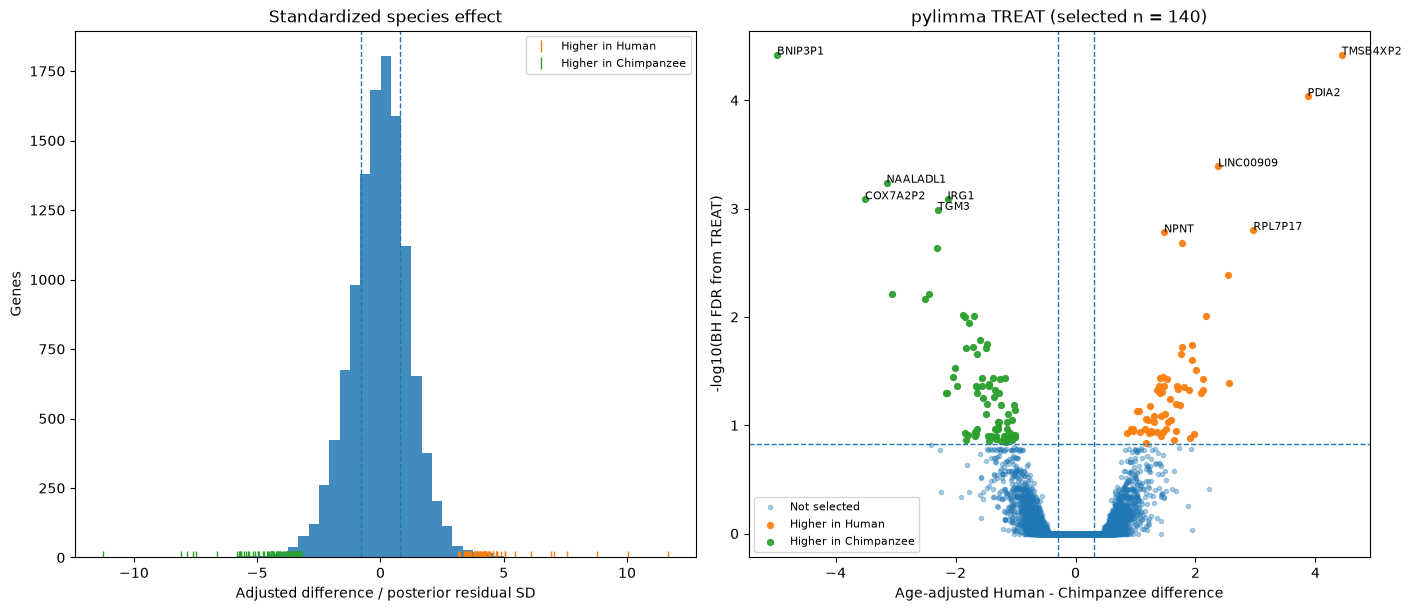

Saved: data/early_human_chimp_pylimma_distribution_human_spec.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
ax = axes[0]
valid_effect = np.isfinite(results["standardized_effect"])
ax.hist(results.loc[valid_effect, "standardized_effect"], bins=55, alpha=0.85)
for value in (-MIN_ABS_STANDARDIZED_EFFECT, MIN_ABS_STANDARDIZED_EFFECT):
    ax.axvline(value, linestyle="--", linewidth=1)
if not candidates.empty:
    for direction in ["Higher in Human", "Higher in Chimpanzee"]:
        sub = candidates.loc[candidates["direction"] == direction, "standardized_effect"]
        if len(sub):
            ax.plot(sub, np.zeros(len(sub)), "|", markersize=9, label=direction)
ax.set(title="Standardized species effect", xlabel="Adjusted difference / posterior residual SD", ylabel="Genes")
if not candidates.empty:
    ax.legend(fontsize=8)

ax = axes[1]
volcano_y = -np.log10(np.clip(results["treat_fdr"].to_numpy(float), np.finfo(float).tiny, 1))
x = results["human_minus_chimp_log2_difference"].to_numpy(float)
ax.scatter(x, volcano_y, s=9, alpha=0.35, label="Not selected")
for direction in ["Higher in Human", "Higher in Chimpanzee"]:
    sel = (results["selected"] & (results["direction"] == direction)).to_numpy()
    if sel.any():
        ax.scatter(x[sel], volcano_y[sel], s=18, alpha=0.9, label=direction)
for value in (-MIN_ABS_LOG2_DIFFERENCE, MIN_ABS_LOG2_DIFFERENCE):
    ax.axvline(value, linestyle="--", linewidth=1)
ax.axhline(-np.log10(MAX_TREAT_FDR), linestyle="--", linewidth=1)
ax.set(title=f"pylimma TREAT (selected n = {len(candidates)})",
       xlabel="Age-adjusted Human - Chimpanzee difference",
       ylabel="-log10(BH FDR from TREAT)")
for row in results.loc[results["selected"]].head(10).itertuples():
    ax.annotate(str(row.Gene), (row.human_minus_chimp_log2_difference,
                               -np.log10(max(row.treat_fdr, np.finfo(float).tiny))), fontsize=8)
ax.legend(fontsize=8)
fig.savefig(DISTRIBUTION_PLOT_FILE, dpi=220)
plt.show()
print("Saved:", DISTRIBUTION_PLOT_FILE)

8. Plot selected gene profiles

Up to 12 selected genes are displayed. If no gene passes, the 12 highest-ranked genes are shown as diagnostics. Both species have the same age slope, so fitted lines are parallel on the log2 age scale.

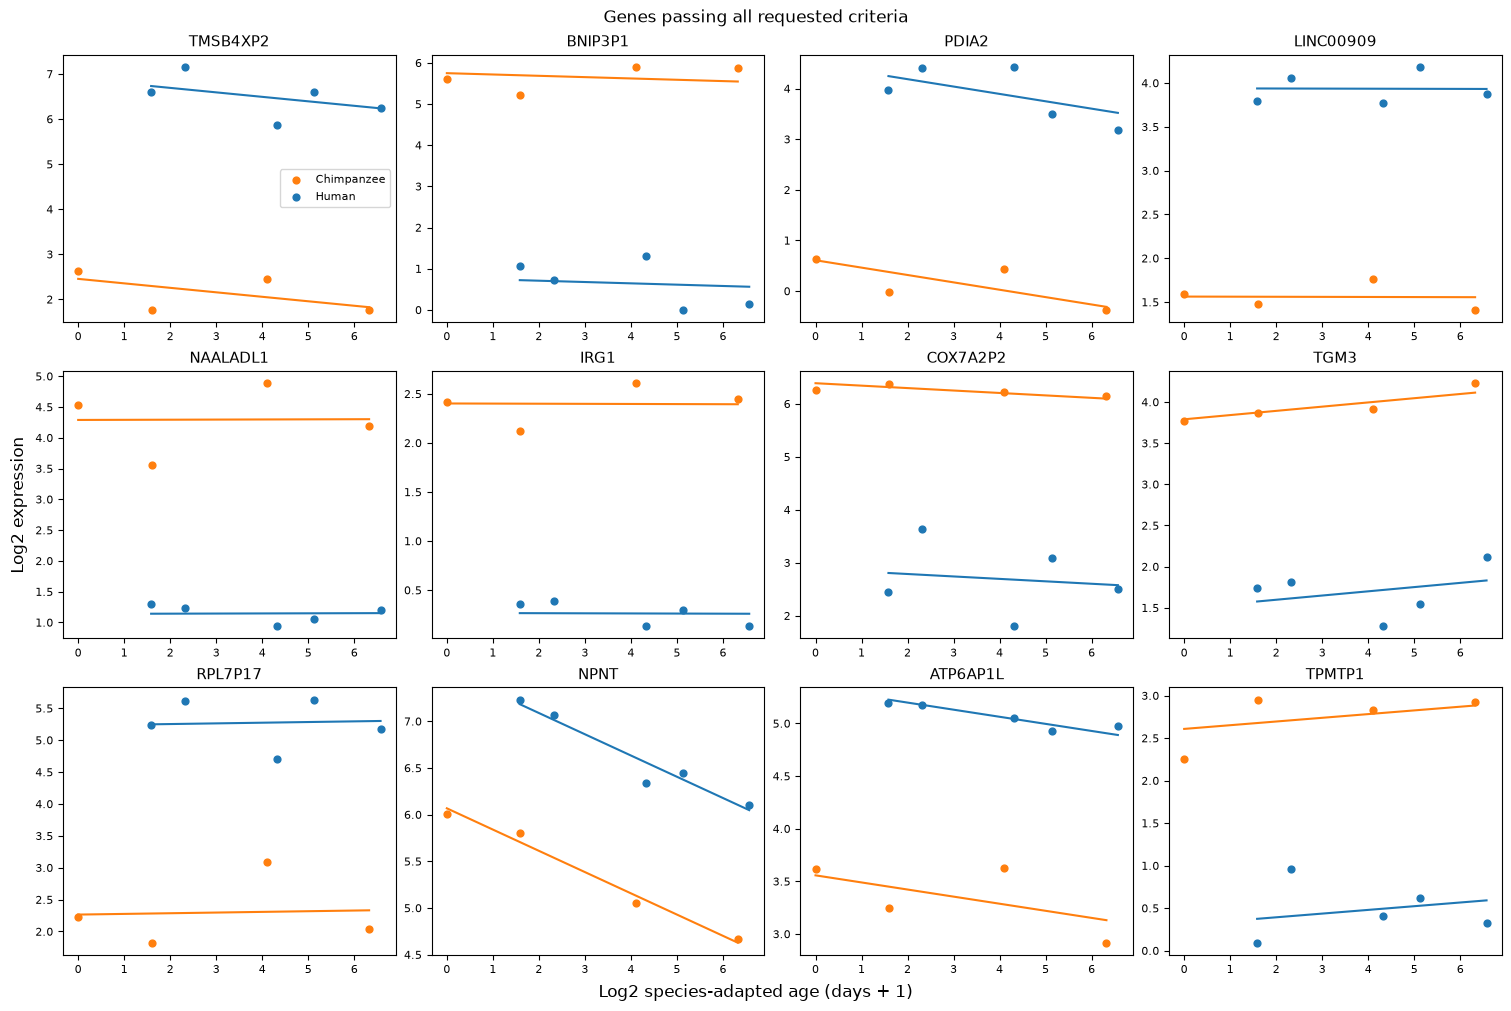

Saved: data/early_human_chimp_pylimma_top_gene_profiles_human_spec.png
Profile genes: TMSB4XP2, BNIP3P1, PDIA2, LINC00909, NAALADL1, IRG1, COX7A2P2, TGM3, RPL7P17, NPNT, ATP6AP1L, TPMTP1


In [8]:
if not candidates.empty:
    profile_genes = candidates["Gene"].head(MAX_PROFILE_GENES).tolist()
    profile_status = "Genes passing all requested criteria"
else:
    profile_genes = results["Gene"].head(MAX_PROFILE_GENES).tolist()
    profile_status = "Top-ranked genes; none passed all criteria"

# Colors use matplotlib's default category cycle.
cycle_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
species_colors = {"Human": cycle_colors[0], "Chimpanzee": cycle_colors[1]}
fig, axes = plt.subplots(3, 4, figsize=(15, 10), constrained_layout=True)
fig.suptitle(profile_status)

for panel_index, ax in enumerate(axes.flat):
    if panel_index >= len(profile_genes):
        ax.axis("off")
        continue
    gene = profile_genes[panel_index]
    gene_i = expr.index.get_loc(gene)
    y = expr.loc[gene, samples].to_numpy(float)
    for species in ["Chimpanzee", "Human"]:
        mask = (early_meta["Species"].astype(str) == species).to_numpy()
        x_species = early_meta.loc[mask, "Log2_species_adapted_age"].to_numpy(float)
        y_species = y[mask]
        ax.scatter(x_species, y_species, color=species_colors[species],
                   s=24, label=species if panel_index == 0 else None)
        x_line = np.linspace(x_species.min(), x_species.max(), 100)
        predictions = (
            full_coefficients[gene_i, 0]
            + full_coefficients[gene_i, 1] * (x_line - age_center)
            + full_coefficients[gene_i, 2] * float(species == "Human")
        )
        ax.plot(x_line, predictions, color=species_colors[species], linewidth=1.5)
    ax.set_title(str(gene), fontsize=11)
    ax.tick_params(labelsize=8)

if profile_genes:
    axes.flat[0].legend(loc="best", fontsize=8)
fig.supxlabel("Log2 species-adapted age (days + 1)")
fig.supylabel("Log2 expression")
fig.savefig(PROFILE_PLOT_FILE, dpi=220)
plt.show()
print("Saved:", PROFILE_PLOT_FILE)
print("Profile genes:", ", ".join(map(str, profile_genes)))